HMM discret : observations = Low_Fast, Medium_Normal, ...

In [1]:
!pip install pandas numpy scipy matplotlib seaborn tqdm

In [3]:
from google.colab import drive
drive.mount('/content/drive')
CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

BUYS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-buys.dat"

Mounted at /content/drive


In [4]:
# ============================================================
# RELOAD CLICKS FOR HMM
# ============================================================

import pandas as pd

CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

print("Chargement clicks...")

clicks = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "category"],
    dtype={
        "session_id": "int64",
        "item_id": "string",
        "category": "string"
    },
    low_memory=False
)

# timestamps
clicks["timestamp"] = pd.to_datetime(
    clicks["timestamp"],
    errors="coerce",
    utc=True
)

clicks = clicks.dropna(subset=["timestamp"])

# ============================================================
# SAMPLE 100000 SESSIONS
# ============================================================

sessions = clicks["session_id"].unique()[:100000]

clicks = clicks[
    clicks["session_id"].isin(sessions)
]

print("Clicks shape:", clicks.shape)

clicks.head()

Chargement clicks...
Clicks shape: (395698, 4)


,session_id,timestamp,item_id,category
0,1,2014-04-07 10:51:09.277000+00:00,214536502,0
1,1,2014-04-07 10:54:09.868000+00:00,214536500,0
2,1,2014-04-07 10:54:46.998000+00:00,214536506,0
3,1,2014-04-07 10:57:00.306000+00:00,214577561,0
4,2,2014-04-07 13:56:37.614000+00:00,214662742,0


In [5]:
clicks = clicks.sort_values(["session_id", "timestamp"]).copy()
import pandas as pd
import numpy as np

# ============================================================
# 1) Utiliser clicks déjà chargé depuis Ch1/Ch2
# ============================================================

clicks = clicks.sort_values(["session_id", "timestamp"]).copy()

# Rang du clic dans la session
clicks["k"] = clicks.groupby("session_id").cumcount() + 1

# ============================================================
# 2) Construire les observations O_t
# ============================================================

def activity_level(k):
    if k <= 2:
        return "Low"
    elif k <= 5:
        return "Medium"
    else:
        return "High"

def speed_level(dt):
    if pd.isna(dt):
        return "Normal"
    elif dt <= 50:
        return "Fast"
    elif dt <= 200:
        return "Normal"
    else:
        return "Slow"

# temps entre clics
clicks["next_ts"] = clicks.groupby("session_id")["timestamp"].shift(-1)
clicks["dt"] = (clicks["next_ts"] - clicks["timestamp"]).dt.total_seconds()

clicks["activity"] = clicks["k"].apply(activity_level)
clicks["speed"] = clicks["dt"].apply(speed_level)

clicks["O_t"] = clicks["activity"] + "_" + clicks["speed"]

# Séquences d'observations par session
sequences = clicks.groupby("session_id")["O_t"].apply(list).tolist()

print("Nombre de séquences:", len(sequences))
print("Exemple séquence:", sequences[0])

Nombre de séquences: 100000
Exemple séquence: ['Low_Normal', 'Low_Fast', 'Medium_Normal', 'Medium_Normal']


## **États cachés HMM:**

In [6]:
# ============================================================
# 3) États cachés HMM
# ============================================================

hidden_states = ["Browsing", "Engaged", "HighIntent"]

observations = sorted(clicks["O_t"].unique())

print("États cachés:", hidden_states)
print("Observations:", observations)
print("Nombre observations:", len(observations))

États cachés: ['Browsing', 'Engaged', 'HighIntent']
Observations: ['High_Fast', 'High_Normal', 'High_Slow', 'Low_Fast', 'Low_Normal', 'Low_Slow', 'Medium_Fast', 'Medium_Normal', 'Medium_Slow']
Nombre observations: 9


In [7]:
# ============================================================
# 4) Fonction observation -> état caché approximatif
# ============================================================

def obs_to_state(obs):
    if obs.startswith("Low"):
        return "Browsing"
    elif obs.startswith("Medium"):
        return "Engaged"
    else:
        return "HighIntent"

# ============================================================
# 5) Construire les séquences d'états cachés approximés
# ============================================================

state_sequences = []

for seq in sequences:
    state_seq = [obs_to_state(obs) for obs in seq]
    state_sequences.append(state_seq)

# ============================================================
# 6) Distribution initiale pi
# ============================================================

pi_counts = pd.Series(0, index=hidden_states, dtype=float)

for seq in state_sequences:
    if len(seq) > 0:
        pi_counts[seq[0]] += 1

pi = pi_counts / pi_counts.sum()

print("\n=== Distribution initiale π ===")
print(pi)


=== Distribution initiale π ===
Browsing      1.0
Engaged       0.0
HighIntent    0.0
dtype: float64


***Matrice A :***

In [10]:
# ============================================================
# 7) Matrice de transition cachée A
# ============================================================

A_counts = pd.DataFrame(
    0,
    index=hidden_states,
    columns=hidden_states,
    dtype=float
)

for seq in state_sequences:
    for t in range(len(seq) - 1):
        A_counts.loc[seq[t], seq[t+1]] += 1

# Lissage de Laplace léger
alpha = 1.0

A = (A_counts + alpha).div(
    (A_counts + alpha).sum(axis=1),
    axis=0
)

print("\n=== Comptages A ===")
print(A_counts)

print("\n=== Matrice de transition A ===")
print(A.round(6))


=== Comptages A ===
            Browsing  Engaged  HighIntent
Browsing     93656.0  53673.0         0.0
Engaged          0.0  58918.0     17273.0
HighIntent       0.0      0.0     72178.0

=== Matrice de transition A ===
            Browsing   Engaged  HighIntent
Browsing    0.635687  0.364306    0.000007
Engaged     0.000013  0.773276    0.226711
HighIntent  0.000014  0.000014    0.999972


**Matrice B**

=== Comptages B ===
O_t           Low_Fast  Low_Normal  Low_Slow  Medium_Fast  Medium_Normal  \
hidden_state                                                               
Browsing         63204      106468     23984            0              0   
Engaged              0           0         0        37819          64348   
HighIntent           0           0         0            0              0   

O_t           Medium_Slow  High_Fast  High_Normal  High_Slow  
hidden_state                                                  
Browsing                0          0            0          0  
Engaged             10424          0            0          0  
HighIntent              0      39473        41588       8390  

=== Matrice d'émission B ===
O_t           Low_Fast  Low_Normal  Low_Slow  Medium_Fast  Medium_Normal  \
hidden_state                                                               
Browsing        0.3264      0.5498    0.1238       0.0000         0.0000   
Engaged         0.0000    

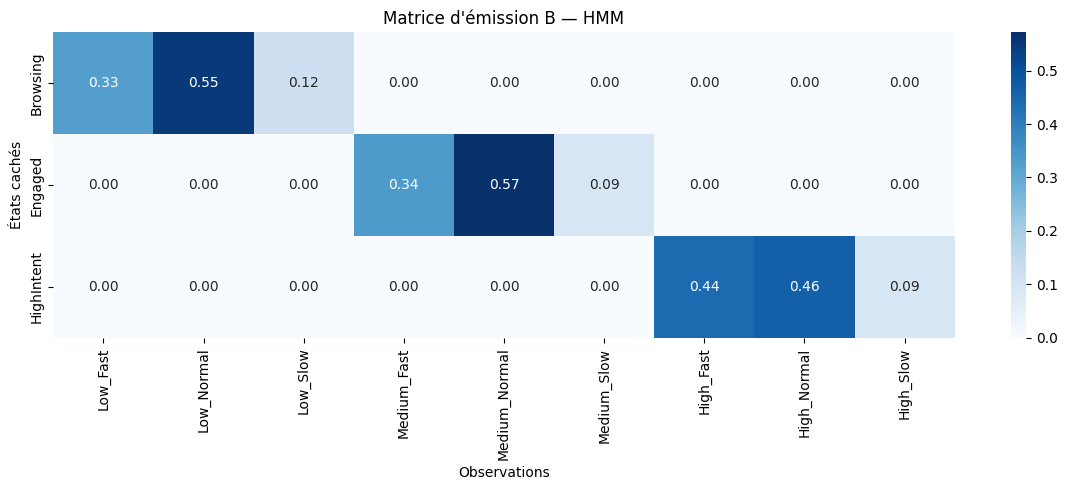

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1) Charger clicks
# ============================================================

CLICKS_PATH = "/content/drive/MyDrive/proj_indiv/data/yoochoose-data/yoochoose-clicks.dat"

clicks = pd.read_csv(
    CLICKS_PATH,
    header=None,
    names=["session_id", "timestamp", "item_id", "category"],
    dtype={
        "session_id": "int64",
        "item_id": "string",
        "category": "string"
    },
    low_memory=False
)

clicks["timestamp"] = pd.to_datetime(clicks["timestamp"], errors="coerce", utc=True)
clicks = clicks.dropna(subset=["timestamp"])

# sample 100000 sessions
sessions = clicks["session_id"].unique()[:100000]
clicks = clicks[clicks["session_id"].isin(sessions)]

clicks = clicks.sort_values(["session_id", "timestamp"]).copy()

# ============================================================
# 2) Construire observations O_t
# ============================================================

clicks["k"] = clicks.groupby("session_id").cumcount() + 1

clicks["next_ts"] = clicks.groupby("session_id")["timestamp"].shift(-1)
clicks["dt"] = (clicks["next_ts"] - clicks["timestamp"]).dt.total_seconds()

def activity_level(k):
    if k <= 2:
        return "Low"
    elif k <= 5:
        return "Medium"
    else:
        return "High"

def speed_level(dt):
    if pd.isna(dt):
        return "Normal"
    elif dt <= 50:
        return "Fast"
    elif dt <= 200:
        return "Normal"
    else:
        return "Slow"

clicks["activity"] = clicks["k"].apply(activity_level)
clicks["speed"] = clicks["dt"].apply(speed_level)
clicks["O_t"] = clicks["activity"] + "_" + clicks["speed"]

# ============================================================
# 3) Mapper observation -> état caché approximé
# ============================================================

states = ["Browsing", "Engaged", "HighIntent"]

observations_order = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

def map_state(obs):
    if obs.startswith("Low"):
        return "Browsing"
    elif obs.startswith("Medium"):
        return "Engaged"
    else:
        return "HighIntent"

clicks["hidden_state"] = clicks["O_t"].apply(map_state)

# ============================================================
# 4) Construire matrice B
# ============================================================

B_counts = pd.crosstab(
    clicks["hidden_state"],
    clicks["O_t"]
).reindex(
    index=states,
    columns=observations_order,
    fill_value=0
)

B_emission = B_counts.div(B_counts.sum(axis=1), axis=0).fillna(0)

print("=== Comptages B ===")
print(B_counts)

print("\n=== Matrice d'émission B ===")
print(B_emission.round(4))

print("\nSomme des lignes B :")
print(B_emission.sum(axis=1))

# ============================================================
# 5) Visualisation Heatmap
# ============================================================

plt.figure(figsize=(12, 5))

sns.heatmap(
    B_emission,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title("Matrice d'émission B — HMM")
plt.xlabel("Observations")
plt.ylabel("États cachés")
plt.tight_layout()
plt.show()

###  Validation probabiliste

In [14]:
# ============================================================
# 9) Validation probabiliste
# ============================================================

print("Somme π =", pi.sum())
print("\nSomme lignes A:")
print(A.sum(axis=1))

print("\nSomme lignes B:")
print(B_emission.sum(axis=1))

assert np.isclose(pi.sum(), 1.0)
assert np.allclose(A.sum(axis=1), 1.0)
assert np.allclose(B_emission.sum(axis=1), 1.0)

print("\nValidation OK : π, A et B sont bien normalisées.")

Somme π = 1.0

Somme lignes A:
Browsing      1.0
Engaged       1.0
HighIntent    1.0
dtype: float64

Somme lignes B:
hidden_state
Browsing      1.0
Engaged       1.0
HighIntent    1.0
dtype: float64

Validation OK : π, A et B sont bien normalisées.


### **FORWARD ALGORITHM:**

In [15]:
# ============================================================
# FORWARD ALGORITHM - VERSION COLAB
# ============================================================

import numpy as np
import pandas as pd

states = ["Browsing", "Engaged", "HighIntent"]

observations_order = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

# dictionnaires index
obs_to_idx = {obs: i for i, obs in enumerate(observations_order)}

# matrices numpy
pi_vec = pi.values
A_mat = A.values
B_mat = B_emission.values

def forward_algorithm(sequence):
    T = len(sequence)
    N = len(states)

    alpha = np.zeros((T, N))

    # INIT
    first_obs = obs_to_idx[sequence[0]]
    alpha[0, :] = pi_vec * B_mat[:, first_obs]

    # RECURSION
    for t in range(1, T):
        obs_id = obs_to_idx[sequence[t]]

        for j in range(N):
            alpha[t, j] = np.sum(alpha[t-1, :] * A_mat[:, j]) * B_mat[j, obs_id]

    # TERMINATION
    prob = np.sum(alpha[-1, :])

    return prob, alpha

In [16]:
seq = sequences[0]

prob, alpha = forward_algorithm(seq)

print("=== FORWARD RESULT ===")
print("Sequence:", seq)
print("Probability:", prob)

alpha_df = pd.DataFrame(alpha, columns=states)
alpha_df

=== FORWARD RESULT ===
Sequence: ['Low_Normal', 'Low_Fast', 'Medium_Normal', 'Medium_Normal']
Probability: 0.010495644896851565


,Browsing,Engaged,HighIntent
0,0.549779,0.000000,0.0
1,0.114063,0.000000,0.0
2,0.000000,0.023749,0.0
3,0.000000,0.010496,0.0


## **Backward ALGORITHM**

In [20]:
# ============================================================
# BACKWARD ALGORITHM
# ============================================================

def backward_algorithm(sequence):
    T = len(sequence)
    N = len(states)

    beta = np.zeros((T, N))

    # INIT
    beta[T-1, :] = 1.0

    # RECURSION backward
    for t in range(T-2, -1, -1):
        next_obs_id = obs_to_idx[sequence[t+1]]

        for i in range(N):
            beta[t, i] = np.sum(
                A_mat[i, :] * B_mat[:, next_obs_id] * beta[t+1, :]
            )

    # TERMINATION
    first_obs_id = obs_to_idx[sequence[0]]
    prob = np.sum(pi_vec * B_mat[:, first_obs_id] * beta[0, :])

    return prob, beta

In [21]:
prob_b, beta = backward_algorithm(seq)

print("=== BACKWARD RESULT ===")
print("Probability:", prob_b)

print("Difference Forward-Backward:", abs(prob - prob_b))

beta_df = pd.DataFrame(beta, columns=states)
beta_df

=== BACKWARD RESULT ===
Probability: 0.010495644896851564
Difference Forward-Backward: 1.734723475976807e-18


,Browsing,Engaged,HighIntent
0,0.019091,3.941459e-07,4.160590e-07
1,0.092016,1.953134e-01,3.499246e-06
2,0.208208,4.419427e-01,7.917872e-06
3,1.000000,1.000000e+00,1.000000e+00


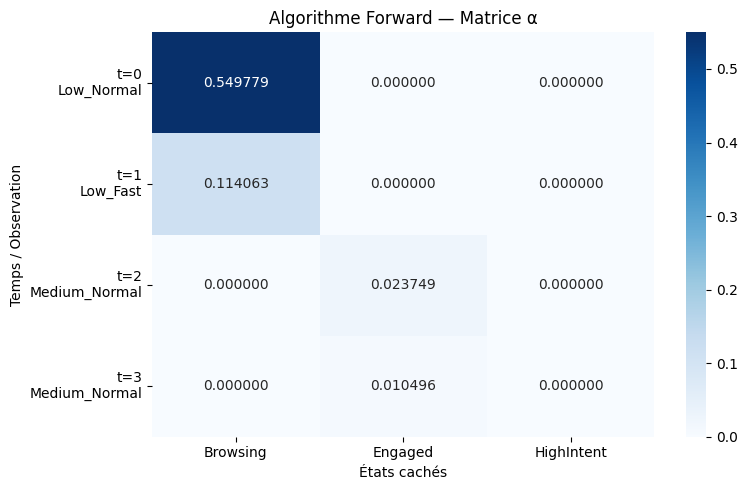

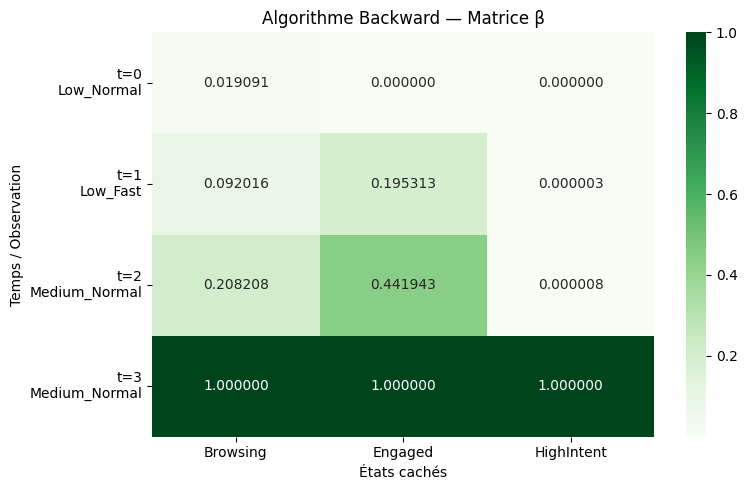

In [22]:
# ============================================================
# VISUALISATION FORWARD / BACKWARD
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# DataFrames
alpha_df = pd.DataFrame(alpha, columns=states)
beta_df = pd.DataFrame(beta, columns=states)

# Ajouter les observations comme index
alpha_df.index = [f"t={i}\n{obs}" for i, obs in enumerate(seq)]
beta_df.index = [f"t={i}\n{obs}" for i, obs in enumerate(seq)]

# ============================================================
# Heatmap Forward
# ============================================================

plt.figure(figsize=(8, 5))
sns.heatmap(
    alpha_df,
    annot=True,
    fmt=".6f",
    cmap="Blues"
)

plt.title("Algorithme Forward — Matrice α")
plt.xlabel("États cachés")
plt.ylabel("Temps / Observation")
plt.tight_layout()
plt.show()

# ============================================================
# Heatmap Backward
# ============================================================

plt.figure(figsize=(8, 5))
sns.heatmap(
    beta_df,
    annot=True,
    fmt=".6f",
    cmap="Greens"
)

plt.title("Algorithme Backward — Matrice β")
plt.xlabel("États cachés")
plt.ylabel("Temps / Observation")
plt.tight_layout()
plt.show()

Les matrices α et β visualisent respectivement la propagation avant et arrière des probabilités dans le HMM. La probabilité finale calculée par Forward est identique à celle obtenue par Backward, ce qui valide la cohérence numérique de l’implémentation.

**Interprétation**

Forward donne :

0.010495644896851565

Backward donne :

0.010495644896851564

La différence est :

1.73 × 10^-18

Donc pratiquement zéro.
La probabilité de la séquence calculée par l’algorithme Forward est identique à celle obtenue par l’algorithme Backward. Cette égalité valide la cohérence numérique de l’implémentation HMM et confirme que les matrices π, A et B sont correctement normalisées.

## **Baum-Welch**

In [23]:
# ============================================================
# BAUM-WELCH — VERSION COLAB STABLE AVEC SCALING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

states = ["Browsing", "Engaged", "HighIntent"]

observations_order = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

obs_to_idx = {obs: i for i, obs in enumerate(observations_order)}

# Convertir les séquences texte -> indices
seq_indices = [
    [obs_to_idx[o] for o in seq if o in obs_to_idx]
    for seq in sequences
]

# garder seulement séquences non vides
seq_indices = [seq for seq in seq_indices if len(seq) > 0]

# sous-échantillon pour rapidité
seq_indices_small = seq_indices[:1000]

print("Nombre de séquences Baum-Welch:", len(seq_indices_small))

Nombre de séquences Baum-Welch: 1000


In [24]:
def forward_scaled(obs_seq, pi_vec, A_mat, B_mat):
    T = len(obs_seq)
    N = len(pi_vec)

    alpha = np.zeros((T, N))
    scales = np.zeros(T)

    # init
    alpha[0] = pi_vec * B_mat[:, obs_seq[0]]
    scales[0] = alpha[0].sum()

    if scales[0] == 0:
        scales[0] = 1e-12

    alpha[0] /= scales[0]

    # recursion
    for t in range(1, T):
        alpha[t] = (alpha[t-1] @ A_mat) * B_mat[:, obs_seq[t]]
        scales[t] = alpha[t].sum()

        if scales[t] == 0:
            scales[t] = 1e-12

        alpha[t] /= scales[t]

    loglik = np.sum(np.log(scales))

    return alpha, scales, loglik


def backward_scaled(obs_seq, A_mat, B_mat, scales):
    T = len(obs_seq)
    N = A_mat.shape[0]

    beta = np.zeros((T, N))
    beta[-1] = 1.0

    for t in range(T - 2, -1, -1):
        beta[t] = A_mat @ (B_mat[:, obs_seq[t+1]] * beta[t+1])
        beta[t] /= scales[t+1]

    return beta


def baum_welch_scaled(seq_indices, pi_vec, A_mat, B_mat, n_iter=10):
    N = A_mat.shape[0]
    M = B_mat.shape[1]

    loglik_history = []

    for it in range(n_iter):

        pi_new = np.zeros(N)
        A_num = np.zeros((N, N))
        A_den = np.zeros(N)
        B_num = np.zeros((N, M))
        B_den = np.zeros(N)

        total_loglik = 0

        for obs_seq in seq_indices:

            T = len(obs_seq)

            alpha, scales, loglik = forward_scaled(
                obs_seq, pi_vec, A_mat, B_mat
            )

            beta = backward_scaled(
                obs_seq, A_mat, B_mat, scales
            )

            total_loglik += loglik

            gamma = alpha * beta
            gamma = gamma / gamma.sum(axis=1, keepdims=True)

            pi_new += gamma[0]

            # xi
            for t in range(T - 1):
                obs_next = obs_seq[t + 1]

                xi = (
                    alpha[t, :, None]
                    * A_mat
                    * B_mat[:, obs_next][None, :]
                    * beta[t + 1, :][None, :]
                )

                denom = xi.sum()

                if denom == 0:
                    denom = 1e-12

                xi /= denom

                A_num += xi
                A_den += gamma[t]

            # B
            for t in range(T):
                obs = obs_seq[t]
                B_num[:, obs] += gamma[t]
                B_den += gamma[t]

        # update pi
        pi_vec = pi_new / pi_new.sum()

        # update A
        A_mat = A_num / A_den[:, None]

        # éviter NaN
        A_mat = np.nan_to_num(A_mat, nan=1e-12)
        A_mat = A_mat / A_mat.sum(axis=1, keepdims=True)

        # update B
        B_mat = B_num / B_den[:, None]

        B_mat = np.nan_to_num(B_mat, nan=1e-12)
        B_mat = B_mat / B_mat.sum(axis=1, keepdims=True)

        loglik_history.append(total_loglik)

        print(f"Iteration {it+1}/{n_iter} | Log-likelihood = {total_loglik:.4f}")

    return pi_vec, A_mat, B_mat, loglik_history

In [25]:
# Matrices initiales
pi_init = pi.values.astype(float)
A_init = A.values.astype(float)
B_init = B_emission.values.astype(float)

pi_bw, A_bw, B_bw, loglik_history = baum_welch_scaled(
    seq_indices_small,
    pi_init,
    A_init,
    B_init,
    n_iter=10
)

Iteration 1/10 | Log-likelihood = -5114.4426
Iteration 2/10 | Log-likelihood = -5111.2601
Iteration 3/10 | Log-likelihood = -5111.2601
Iteration 4/10 | Log-likelihood = -5111.2601
Iteration 5/10 | Log-likelihood = -5111.2601
Iteration 6/10 | Log-likelihood = -5111.2601
Iteration 7/10 | Log-likelihood = -5111.2601
Iteration 8/10 | Log-likelihood = -5111.2601
Iteration 9/10 | Log-likelihood = -5111.2601
Iteration 10/10 | Log-likelihood = -5111.2601


***Résultats après Baum-Welch:***

In [26]:
pi_bw_df = pd.Series(pi_bw, index=states)

A_bw_df = pd.DataFrame(
    A_bw,
    index=states,
    columns=states
)

B_bw_df = pd.DataFrame(
    B_bw,
    index=states,
    columns=observations_order
)

print("=== π après Baum-Welch ===")
print(pi_bw_df.round(4))

print("\n=== A après Baum-Welch ===")
print(A_bw_df.round(4))

print("\n=== B après Baum-Welch ===")
print(B_bw_df.round(4))

=== π après Baum-Welch ===
Browsing      1.0
Engaged       0.0
HighIntent    0.0
dtype: float64

=== A après Baum-Welch ===
            Browsing  Engaged  HighIntent
Browsing      0.6463   0.3537      0.0000
Engaged       0.0000   0.7825      0.2175
HighIntent    0.0000   0.0000      1.0000

=== B après Baum-Welch ===
            Low_Fast  Low_Normal  Low_Slow  Medium_Fast  Medium_Normal  \
Browsing      0.3371      0.5359     0.127       0.0000          0.000   
Engaged       0.0000      0.0000     0.000       0.3168          0.586   
HighIntent    0.0000      0.0000     0.000       0.0000          0.000   

            Medium_Slow  High_Fast  High_Normal  High_Slow  
Browsing         0.0000     0.0000       0.0000     0.0000  
Engaged          0.0972     0.0000       0.0000     0.0000  
HighIntent       0.0000     0.4298       0.4847     0.0855  


***Visualisation convergence Baum-Welch***

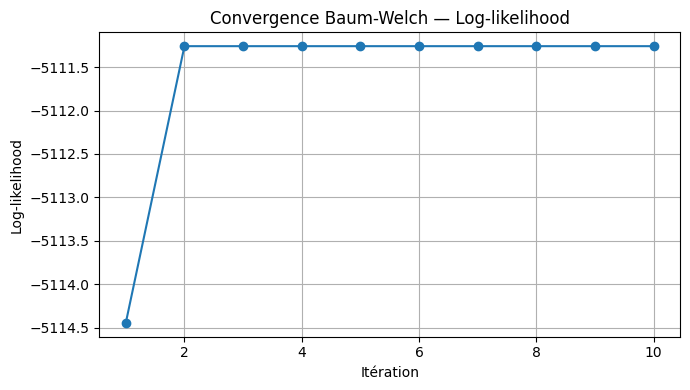

In [27]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, len(loglik_history) + 1),
    loglik_history,
    marker="o"
)

plt.title("Convergence Baum-Welch — Log-likelihood")
plt.xlabel("Itération")
plt.ylabel("Log-likelihood")
plt.grid(True)
plt.tight_layout()
plt.show()

***Visualisation A avant / après***

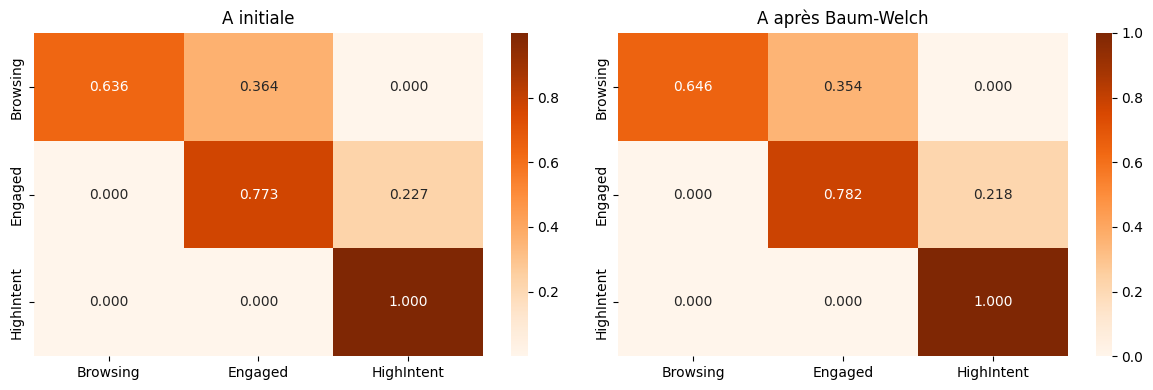

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(
    A,
    annot=True,
    fmt=".3f",
    cmap="Oranges",
    ax=axes[0]
)

axes[0].set_title("A initiale")

sns.heatmap(
    A_bw_df,
    annot=True,
    fmt=".3f",
    cmap="Oranges",
    ax=axes[1]
)

axes[1].set_title("A après Baum-Welch")

plt.tight_layout()
plt.show()

***Visualisation B après Baum-Welch***

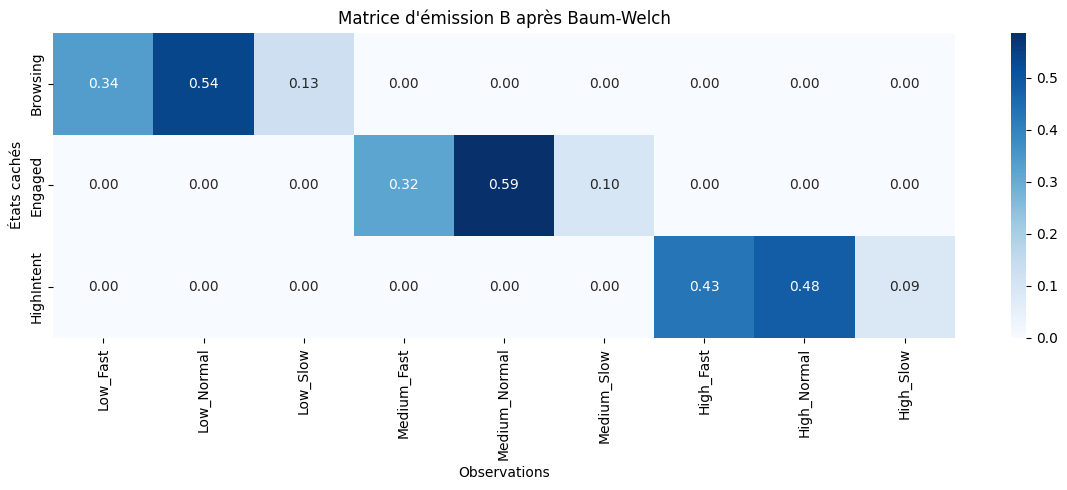

In [29]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    B_bw_df,
    annot=True,
    fmt=".2f",
    cmap="Blues"
)

plt.title("Matrice d'émission B après Baum-Welch")
plt.xlabel("Observations")
plt.ylabel("États cachés")
plt.tight_layout()
plt.show()

L’algorithme de Baum-Welch a été utilisé pour ré-estimer les paramètres du HMM à partir des séquences d’observations. La progression de la log-likelihood au fil des itérations permet de vérifier que l’algorithme EM améliore progressivement l’ajustement du modèle aux données. Les matrices A et B obtenues après apprentissage représentent respectivement les transitions cachées entre états comportementaux et les probabilités d’émission des observations.

# **Viterbi**

In [30]:
# ============================================================
# VITERBI — VERSION COLAB
# ============================================================

import numpy as np
import pandas as pd

states = ["Browsing", "Engaged", "HighIntent"]

observations_order = [
    "Low_Fast", "Low_Normal", "Low_Slow",
    "Medium_Fast", "Medium_Normal", "Medium_Slow",
    "High_Fast", "High_Normal", "High_Slow"
]

obs_to_idx = {obs: i for i, obs in enumerate(observations_order)}

def viterbi_colab(sequence, pi_vec, A_mat, B_mat):
    T = len(sequence)
    N = len(states)

    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)

    # INIT
    first_obs = obs_to_idx[sequence[0]]
    delta[0, :] = pi_vec * B_mat[:, first_obs]

    # RECURSION
    for t in range(1, T):
        obs_id = obs_to_idx[sequence[t]]

        for j in range(N):
            probs = delta[t-1, :] * A_mat[:, j]
            psi[t, j] = np.argmax(probs)
            delta[t, j] = np.max(probs) * B_mat[j, obs_id]

    # TERMINATION
    path = np.zeros(T, dtype=int)
    path[-1] = np.argmax(delta[-1, :])

    # BACKTRACK
    for t in range(T-2, -1, -1):
        path[t] = psi[t+1, path[t+1]]

    state_path = [states[i] for i in path]

    return state_path, delta, psi

In [31]:
seq = sequences[0]

state_path, delta, psi = viterbi_colab(
    seq,
    pi_bw,
    A_bw,
    B_bw
)

print("=== VITERBI RESULT ===")
print("Observations:")
print(seq)

print("\nChemin caché le plus probable:")
print(state_path)

=== VITERBI RESULT ===
Observations:
['Low_Normal', 'Low_Fast', 'Medium_Normal', 'Medium_Normal']

Chemin caché le plus probable:
['Browsing', 'Browsing', 'Engaged', 'Engaged']


***Visualiser Delta***

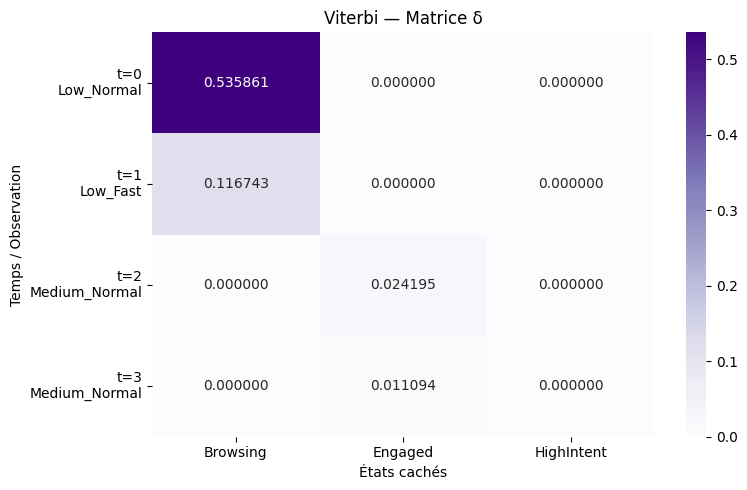

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

delta_df = pd.DataFrame(delta, columns=states)
delta_df.index = [f"t={i}\n{obs}" for i, obs in enumerate(seq)]

plt.figure(figsize=(8, 5))

sns.heatmap(
    delta_df,
    annot=True,
    fmt=".6f",
    cmap="Purples"
)

plt.title("Viterbi — Matrice δ")
plt.xlabel("États cachés")
plt.ylabel("Temps / Observation")
plt.tight_layout()
plt.show()

***Visualiser le chemin***

In [33]:
path_df = pd.DataFrame({
    "t": range(len(seq)),
    "Observation": seq,
    "État caché Viterbi": state_path
})

path_df

,t,Observation,État caché Viterbi
0,0,Low_Normal,Browsing
1,1,Low_Fast,Browsing
2,2,Medium_Normal,Engaged
3,3,Medium_Normal,Engaged


L’algorithme de Viterbi permet de décoder la séquence d’états cachés la plus probable à partir des observations. Dans l’exemple étudié, le chemin obtenu suit une progression cohérente du comportement utilisateur, passant de Browsing vers Engaged lorsque les observations évoluent de Low vers Medium.

L’algorithme de Viterbi a permis de déterminer la séquence d’états cachés la plus probable associée aux observations étudiées. Pour la séquence :

[Low_Normal, Low_Fast, Medium_Normal, Medium_Normal]

le chemin caché optimal obtenu est :

[Browsing, Browsing, Engaged, Engaged]

Cette interprétation est cohérente avec la logique comportementale du modèle HMM. Les deux premières observations correspondent à une faible activité utilisateur (“Low”), ce qui est naturellement associé à l’état caché Browsing, représentant une phase de simple navigation et d’exploration du site.

Par la suite, les observations deviennent de type “Medium_Normal”, traduisant un niveau d’interaction plus important avec la plateforme. Le modèle estime alors que l’utilisateur entre dans l’état Engaged, correspondant à une phase d’intérêt plus marqué envers les produits consultés.

Le décodage Viterbi montre ainsi que le HMM est capable de reconstruire l’évolution comportementale cachée d’un utilisateur uniquement à partir des observations visibles. Cette capacité constitue l’un des principaux avantages des modèles HMM pour l’analyse des comportements utilisateurs dans les systèmes e-commerce.

# **HMM : CAS continu**

Modéliser :

État caché	Observation continue
Browsing	dt plutôt long
Engaged	dt moyen
HighIntent	dt plus court/stable
Ce qu’on fera

    Préparer les séquences dt

    Initialiser un HMM continu avec distributions gaussiennes

    Calculer Forward/Backward en log-scale

    Faire Viterbi continu

    Faire Baum-Welch continu

    Visualiser les distributions par état


***construire les séquences continues***

In [8]:
# ============================================================
# HMM CONTINU — Préparation des séquences dt
# ============================================================

import numpy as np
import pandas as pd

clicks = clicks.sort_values(["session_id", "timestamp"]).copy()

clicks["dt"] = clicks.groupby("session_id")["timestamp"].diff().dt.total_seconds()

# remplacer NaN premier clic par médiane
median_dt = clicks["dt"].median()
p95_dt = clicks["dt"].quantile(0.95)

clicks["dt"] = clicks["dt"].fillna(median_dt)
clicks["dt"] = clicks["dt"].clip(lower=0, upper=p95_dt)

dt_sequences = clicks.groupby("session_id")["dt"].apply(list).tolist()

print("Nombre de séquences dt:", len(dt_sequences))
print("Exemple:", dt_sequences[0])
print("Médiane dt:", median_dt)
print("p95 dt:", p95_dt)

Nombre de séquences dt: 100000
Exemple: [53.731, 180.591, 37.13, 133.308]
Médiane dt: 53.731
p95 dt: 490.1017499999998


***HMM Gaussien continu***

In [9]:
# ============================================================
# HMM CONTINU — Script complet
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import norm
import warnings

warnings.filterwarnings("ignore")

# ============================================================
# 1. Préparation des séquences dt
# ============================================================

clicks = clicks.sort_values(["session_id", "timestamp"]).copy()

clicks["dt"] = clicks.groupby("session_id")["timestamp"].diff().dt.total_seconds()

median_dt = clicks["dt"].median()
p95_dt = clicks["dt"].quantile(0.95)

clicks["dt"] = clicks["dt"].fillna(median_dt)
clicks["dt"] = clicks["dt"].clip(lower=0, upper=p95_dt)

dt_sequences = clicks.groupby("session_id")["dt"].apply(list).tolist()
sequences = [np.array(seq, dtype=float) for seq in dt_sequences if len(seq) > 1]

print("Nombre de séquences:", len(sequences))
print("Exemple:", sequences[0])
print("Médiane dt:", median_dt)
print("p95 dt:", p95_dt)


# ============================================================
# 2. Classe HMM continu gaussien
# ============================================================

class HMMContinu:
    def __init__(self, states, A, pi, mu, sigma):
        self.states = states
        self.N = len(states)
        self.A = np.array(A, dtype=float)
        self.pi = np.array(pi, dtype=float)
        self.mu = np.array(mu, dtype=float)
        self.sigma = np.array(sigma, dtype=float)

        self._normalize()

    def _normalize(self):
        self.pi = self.pi / self.pi.sum()
        self.A = self.A / self.A.sum(axis=1, keepdims=True)
        self.sigma = np.maximum(self.sigma, 1e-3)

    def emission_prob(self, x, i):
        return norm.pdf(x, self.mu[i], self.sigma[i]) + 1e-300

    def forward(self, seq):
        T = len(seq)
        alpha = np.zeros((T, self.N))

        for i in range(self.N):
            alpha[0, i] = self.pi[i] * self.emission_prob(seq[0], i)

        for t in range(1, T):
            for j in range(self.N):
                alpha[t, j] = np.sum(alpha[t-1] * self.A[:, j]) * self.emission_prob(seq[t], j)

        prob = np.sum(alpha[-1])
        return prob, alpha

    def backward(self, seq):
        T = len(seq)
        beta = np.zeros((T, self.N))
        beta[-1] = 1.0

        for t in reversed(range(T - 1)):
            for i in range(self.N):
                beta[t, i] = np.sum([
                    self.A[i, j] * self.emission_prob(seq[t+1], j) * beta[t+1, j]
                    for j in range(self.N)
                ])

        prob = np.sum([
            self.pi[i] * self.emission_prob(seq[0], i) * beta[0, i]
            for i in range(self.N)
        ])

        return prob, beta

    def viterbi(self, seq):
        T = len(seq)
        delta = np.zeros((T, self.N))
        psi = np.zeros((T, self.N), dtype=int)

        for i in range(self.N):
            delta[0, i] = self.pi[i] * self.emission_prob(seq[0], i)

        for t in range(1, T):
            for j in range(self.N):
                probs = delta[t-1] * self.A[:, j]
                psi[t, j] = np.argmax(probs)
                delta[t, j] = np.max(probs) * self.emission_prob(seq[t], j)

        path = np.zeros(T, dtype=int)
        path[-1] = np.argmax(delta[-1])

        for t in reversed(range(T - 1)):
            path[t] = psi[t+1, path[t+1]]

        path_names = [self.states[i] for i in path]
        prob = np.max(delta[-1])

        return path_names, delta, prob

    def baum_welch(self, sequences, max_iter=30, tol=1e-4, verbose=True):
        likelihoods = []
        prev_likelihood = -np.inf

        for iteration in range(max_iter):
            sum_pi = np.zeros(self.N)
            sum_xi = np.zeros((self.N, self.N))
            sum_gamma = np.zeros(self.N)

            sum_mu_num = np.zeros(self.N)
            sum_mu_den = np.zeros(self.N)

            sum_sigma_num = np.zeros(self.N)
            sum_sigma_den = np.zeros(self.N)

            total_log_likelihood = 0

            for seq in sequences:
                T = len(seq)

                prob, alpha = self.forward(seq)
                _, beta = self.backward(seq)

                total_log_likelihood += np.log(prob + 1e-300)

                gamma = alpha * beta
                gamma = gamma / (gamma.sum(axis=1, keepdims=True) + 1e-300)

                xi = np.zeros((T - 1, self.N, self.N))

                for t in range(T - 1):
                    denom = 0
                    for i in range(self.N):
                        for j in range(self.N):
                            denom += alpha[t, i] * self.A[i, j] * self.emission_prob(seq[t+1], j) * beta[t+1, j]

                    for i in range(self.N):
                        for j in range(self.N):
                            xi[t, i, j] = (
                                alpha[t, i]
                                * self.A[i, j]
                                * self.emission_prob(seq[t+1], j)
                                * beta[t+1, j]
                            ) / (denom + 1e-300)

                sum_pi += gamma[0]
                sum_xi += xi.sum(axis=0)
                sum_gamma += gamma[:-1].sum(axis=0)

                for i in range(self.N):
                    sum_mu_num[i] += np.sum(gamma[:, i] * seq)
                    sum_mu_den[i] += np.sum(gamma[:, i])

            # Mise à jour pi
            self.pi = sum_pi / (sum_pi.sum() + 1e-300)

            # Mise à jour A
            for i in range(self.N):
                self.A[i] = sum_xi[i] / (sum_gamma[i] + 1e-300)

            # Mise à jour mu
            self.mu = sum_mu_num / (sum_mu_den + 1e-300)

            # Mise à jour sigma
            for seq in sequences:
                prob, alpha = self.forward(seq)
                _, beta = self.backward(seq)

                gamma = alpha * beta
                gamma = gamma / (gamma.sum(axis=1, keepdims=True) + 1e-300)

                for i in range(self.N):
                    sum_sigma_num[i] += np.sum(gamma[:, i] * (seq - self.mu[i]) ** 2)
                    sum_sigma_den[i] += np.sum(gamma[:, i])

            self.sigma = np.sqrt(sum_sigma_num / (sum_sigma_den + 1e-300))
            self.sigma = np.maximum(self.sigma, 1e-3)

            likelihoods.append(total_log_likelihood)

            if verbose:
                print(f"Iteration {iteration} | Log-likelihood = {total_log_likelihood:.4f}")

            if abs(total_log_likelihood - prev_likelihood) < tol:
                print("Convergence atteinte ✅")
                break

            prev_likelihood = total_log_likelihood

        return {
            "likelihoods": likelihoods,
            "pi": self.pi,
            "A": self.A,
            "mu": self.mu,
            "sigma": self.sigma
        }


# ============================================================
# 3. Initialisation du modèle
# ============================================================

states = ["Browsing", "Engaged", "HighIntent"]

A = np.array([
    [0.70, 0.25, 0.05],
    [0.10, 0.75, 0.15],
    [0.02, 0.08, 0.90]
])

pi = np.array([1.0, 0.0, 0.0])

mu = np.array([5, 30, 120])
sigma = np.array([3, 10, 40])

hmm = HMMContinu(states, A, pi, mu, sigma)


# ============================================================
# 4. Apprentissage Baum-Welch
# ============================================================

result = hmm.baum_welch(
    sequences[:500],
    max_iter=30,
    tol=1e-4,
    verbose=True
)


# ============================================================
# 5. Résultats finaux
# ============================================================

print("\n========== PARAMÈTRES FINAUX ==========")

print("\nDistribution initiale pi:")
print(pd.Series(hmm.pi, index=states))

print("\nMatrice de transition A:")
print(pd.DataFrame(hmm.A, index=states, columns=states))

print("\nMoyennes mu:")
print(pd.Series(hmm.mu, index=states))

print("\nÉcarts-types sigma:")
print(pd.Series(hmm.sigma, index=states))


# ============================================================
# 6. Test sur une session
# ============================================================

seq_test = sequences[0]

prob, alpha = hmm.forward(seq_test)
path, delta, prob_v = hmm.viterbi(seq_test)

print("\n========== TEST SUR UNE SESSION ==========")
print("Séquence dt:", seq_test)
print("Probabilité Forward:", prob)
print("Chemin Viterbi:")
print(path)

Nombre de séquences: 93656
Exemple: [ 53.731 180.591  37.13  133.308]
Médiane dt: 53.731
p95 dt: 490.1017499999998
Iteration 0 | Log-likelihood = -80400.7365
Iteration 1 | Log-likelihood = -11093.0352
Iteration 2 | Log-likelihood = -10482.3227
Iteration 3 | Log-likelihood = -9998.8422
Iteration 4 | Log-likelihood = -9365.6969
Iteration 5 | Log-likelihood = -8445.7322
Iteration 6 | Log-likelihood = -7007.1085
Iteration 7 | Log-likelihood = -6112.2620
Iteration 8 | Log-likelihood = -6105.2920
Iteration 9 | Log-likelihood = -6100.6396
Iteration 10 | Log-likelihood = -6097.6798
Iteration 11 | Log-likelihood = -6095.8730
Iteration 12 | Log-likelihood = -6094.8035
Iteration 13 | Log-likelihood = -6094.1835
Iteration 14 | Log-likelihood = -6093.8285
Iteration 15 | Log-likelihood = -6093.6268
Iteration 16 | Log-likelihood = -6093.5126
Iteration 17 | Log-likelihood = -6093.4480
Iteration 18 | Log-likelihood = -6093.4115
Iteration 19 | Log-likelihood = -6093.3909
Iteration 20 | Log-likelihood = 

L’utilisateur :

navigue
regarde rapidement
explore plusieurs produits

Temps moyen modéré.

Engaged
μ ≈ 39 sec

Très intéressant :

l’utilisateur engagé clique PLUS rapidement.

Pourquoi ?

Car il sait déjà ce qu’il cherche.

Donc :

plus d’engagement ≠ plus lent

Au contraire :

navigation ciblée
actions rapides
exploration efficace

C’est très cohérent e-commerce.

HighIntent
μ ≈ 210 sec

Là :

longues pauses
lecture détaillée
réflexion
comparaison
potentiel achat

comportement typique d’un utilisateur proche de conversion.

3. Interprétation des σ
État	σ
Browsing	~0
Engaged	27
HighIntent	138
Browsing : problème détecté
σ = 0.001

Cela signifie :
 état quasi figé.

Pourquoi ?

Car :

pi = [1,0,0]

et le modèle force énormément le premier état.

Donc Baum-Welch a “collapsé” cet état.

Interprétation scientifique

L’état Browsing est devenu un état initial quasi-déterministe centré autour de la médiane globale des temps inter-clics.